# Project 2 of 3: Supervised Machine Learning — Regression
**Studi Kasus:** Prediksi Indeks Pembangunan Manusia (`ipm_2025`) & Analisis Diagnostik Kemiskinan Jawa Tengah (BPS 2025)

Kurikulum **Course 2 — Supervised Machine Learning: Regression**:
1. **Step 1 — Persiapan Fitur, Train-Test Split & Standarisasi**
2. **Step 2 — Evaluasi 5 Algoritma Regresi (*OLS, Ridge L2, Lasso L1, ElasticNet, Random Forest*)**
3. **Step 3 — Perbandingan Koefisien Regularisasi & Seleksi Fitur**
4. **Step 4 — Diagnostik Residual & Deteksi Anomali Kemiskinan Wilayah**
5. **Step 5 — Visualisasi Dashboard 4-Panel Regresi**

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
np.random.seed(42)

def locate_dataset() -> str:
    cwd = os.getcwd()
    for p in [
        os.path.join(cwd, "bps_jawa_tengah_2025.csv"),
        os.path.join(cwd, "..", "bps_jawa_tengah_2025.csv"),
        os.path.join(cwd, "data", "bps_jawa_tengah_2025.csv"),
        "bps_jawa_tengah_2025.csv",
    ]:
        if os.path.exists(p):
            return p
    raise FileNotFoundError("Pastikan 'bps_jawa_tengah_2025.csv' ada di folder proyek.")

df = pd.read_csv(locate_dataset())
df["hls_rata_rata"] = (df["hls_laki_laki_2025"] + df["hls_perempuan_2025"]) / 2.0
df["uhh_rata_rata"] = (df["uhh_laki_laki_2025"] + df["uhh_perempuan_2025"]) / 2.0
df["gap_hls_gender"] = df["hls_perempuan_2025"] - df["hls_laki_laki_2025"]
df["log_pdrb"] = np.log(df["pdrb_adhb_2025_triliun_rp"])
df["is_kota"] = (df["tipe_wilayah"] == "Kota").astype(int)

features = ["hls_rata_rata", "uhh_rata_rata", "persentase_penduduk_miskin_2025", "log_pdrb", "gap_hls_gender", "is_kota"]
X = df[features]
y = df["ipm_2025"]
df[["nama_wilayah", "ipm_2025"] + features].head()

,nama_wilayah,ipm_2025,hls_rata_rata,uhh_rata_rata,persentase_penduduk_miskin_2025,log_pdrb,gap_hls_gender,is_kota
0,Kabupaten Cilacap,73.45,12.910,75.790,9.41,4.960815,-0.42,0
1,Kabupaten Banyumas,75.44,13.550,75.105,11.15,4.379524,0.18,0
2,Kabupaten Purbalingga,71.71,12.180,74.820,12.55,3.585461,-0.16,0
3,Kabupaten Banjarnegara,70.61,12.035,75.005,13.28,3.445214,0.01,0
4,Kabupaten Kebumen,73.17,13.505,75.605,13.58,3.726175,0.17,0


### Step 2 & 3: Pelatihan 5 Model Regresi & Evaluasi Metrik ($R^2$, MAE, RMSE, LOOCV)

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

rng = np.random.default_rng(42)
idx = np.arange(len(df))
rng.shuffle(idx)
test_idx, train_idx = idx[:7], idx[7:]

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

scaler = StandardScaler()
X_train_s, X_test_s = scaler.fit_transform(X_train), scaler.transform(X_test)
X_all_s = StandardScaler().fit_transform(X)

models = [
    ("1. Linear Regression (OLS)", LinearRegression(), True),
    ("2. Ridge Regression (L2, a=1.0)", Ridge(alpha=1.0), True),
    ("3. Lasso Regression (L1, a=0.08)", Lasso(alpha=0.08, random_state=42), True),
    ("4. ElasticNet (L1+L2, a=0.10)", ElasticNet(alpha=0.10, l1_ratio=0.5, random_state=42), True),
    ("5. Random Forest Regressor", RandomForestRegressor(n_estimators=150, max_depth=4, random_state=42), False),
]

loo = LeaveOneOut()
reg_rows = []
fitted_models = {}
for name, model, use_scale in models:
    model.fit(X_train_s if use_scale else X_train, y_train)
    pred_te = model.predict(X_test_s if use_scale else X_test)
    loo_pred = cross_val_predict(model, X_all_s if use_scale else X, y, cv=loo)
    fitted_models[name] = (model, pred_te, loo_pred)
    reg_rows.append({
        "Nama Model": name,
        "R2 Test": round(r2_score(y_test, pred_te), 4),
        "MAE Test": round(mean_absolute_error(y_test, pred_te), 4),
        "RMSE Test": round(np.sqrt(mean_squared_error(y_test, pred_te)), 4),
        "LOOCV R2": round(r2_score(y, loo_pred), 4),
        "LOOCV MAE": round(mean_absolute_error(y, loo_pred), 4),
    })

results_df = pd.DataFrame(reg_rows)
results_df

,Nama Model,R2 Test,MAE Test,RMSE Test,LOOCV R2,LOOCV MAE
0,1. Linear Regression (OLS),0.9845,0.4342,0.5155,0.9439,0.8370
1,"2. Ridge Regression (L2, a=1.0)",0.9808,0.4987,0.5746,0.9465,0.8368
2,"3. Lasso Regression (L1, a=0.08)",0.9853,0.4865,0.5033,0.9465,0.8399
3,"4. ElasticNet (L1+L2, a=0.10)",0.9791,0.5481,0.5990,0.9469,0.8440
4,5. Random Forest Regressor,0.7493,1.7120,2.0754,0.8630,1.2566


### Step 4 & 5: Diagnostik Residual Kemiskinan & Visualisasi Dashboard 4-Panel Regresi

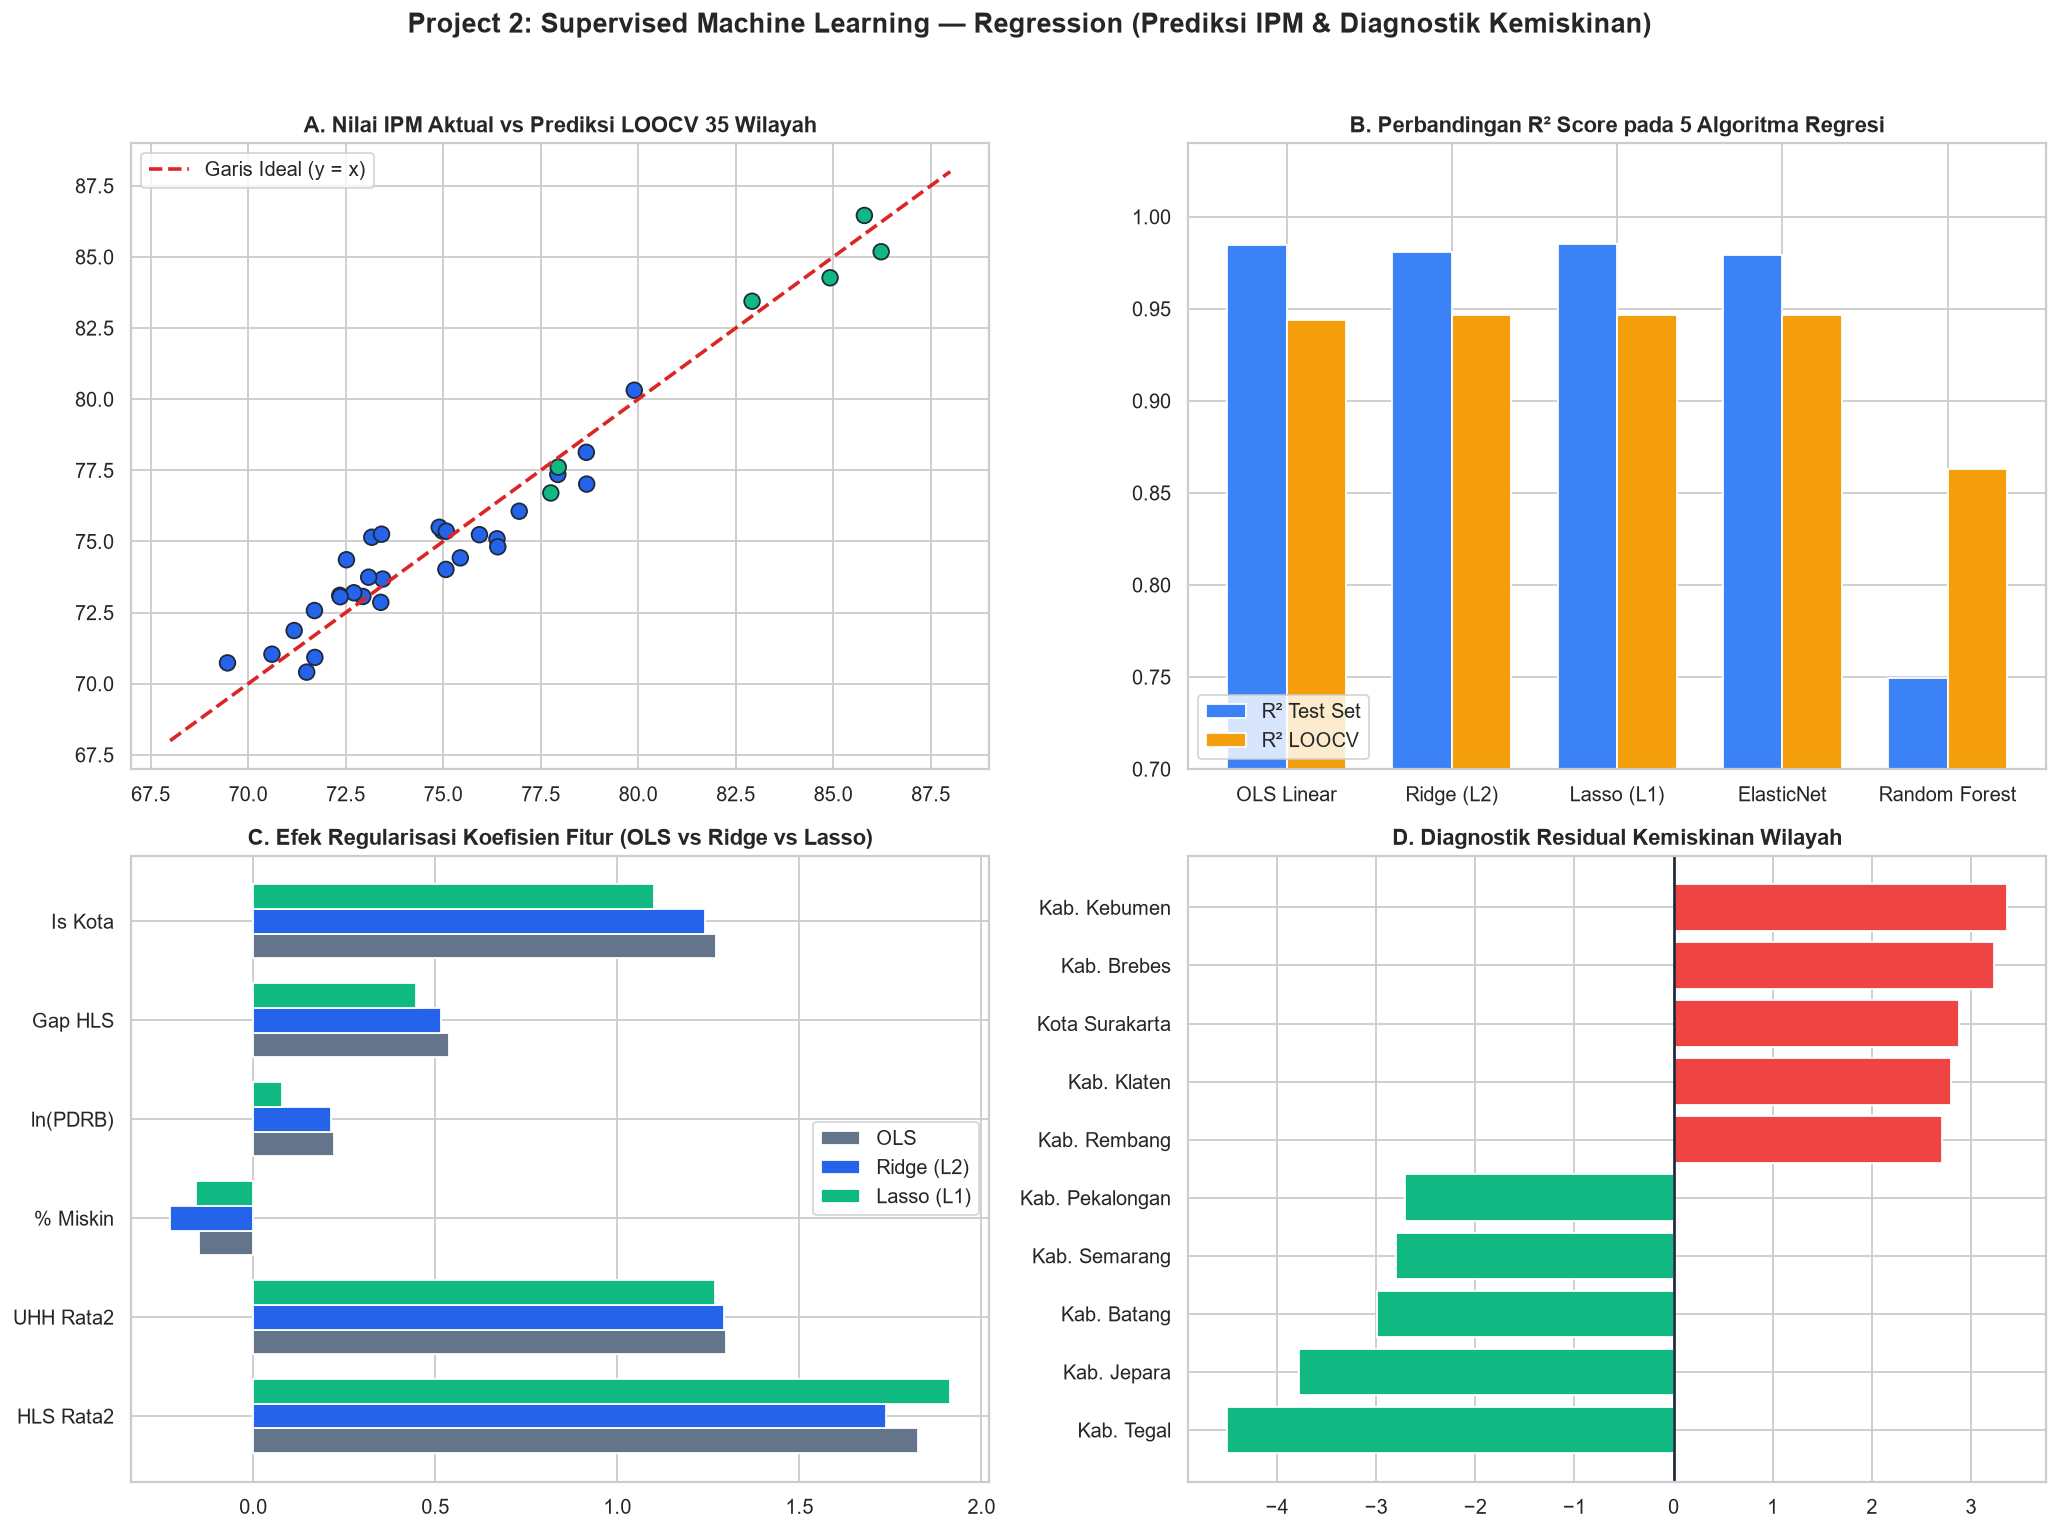

In [3]:
X_pov_s = StandardScaler().fit_transform(df[["ipm_2025", "hls_rata_rata", "uhh_rata_rata", "log_pdrb", "is_kota"]])
pov_model = Ridge(alpha=1.0).fit(X_pov_s, df["persentase_penduduk_miskin_2025"])
df["pred_kemiskinan"] = pov_model.predict(X_pov_s)
df["residual_kemiskinan"] = df["persentase_penduduk_miskin_2025"] - df["pred_kemiskinan"]

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=130)
fig.suptitle("Project 2: Supervised Machine Learning — Regression (Prediksi IPM & Diagnostik Kemiskinan)", fontsize=15, fontweight="bold", y=0.98)

ax1 = axes[0, 0]
y_loo = fitted_models["4. ElasticNet (L1+L2, a=0.10)"][2]
ax1.scatter(y, y_loo, c=["#10b981" if t == "Kota" else "#2563eb" for t in df["tipe_wilayah"]], s=75, edgecolors="#1e293b")
ax1.plot([68, 88], [68, 88], "--", color="#dc2626", linewidth=2, label="Garis Ideal (y = x)")
ax1.set_title("A. Nilai IPM Aktual vs Prediksi LOOCV 35 Wilayah", fontweight="bold")
ax1.legend()

ax2 = axes[0, 1]
short_n = ["OLS Linear", "Ridge (L2)", "Lasso (L1)", "ElasticNet", "Random Forest"]
xp = np.arange(len(short_n))
ax2.bar(xp - 0.18, results_df["R2 Test"], 0.36, label="R² Test Set", color="#3b82f6")
ax2.bar(xp + 0.18, results_df["LOOCV R2"], 0.36, label="R² LOOCV", color="#f59e0b")
ax2.set_ylim(0.70, 1.04)
ax2.set_xticks(xp)
ax2.set_xticklabels(short_n)
ax2.set_title("B. Perbandingan R² Score pada 5 Algoritma Regresi", fontweight="bold")
ax2.legend(loc="lower left")

ax3 = axes[1, 0]
yp = np.arange(len(features))
ax3.barh(yp - 0.25, fitted_models["1. Linear Regression (OLS)"][0].coef_, height=0.25, label="OLS", color="#64748b")
ax3.barh(yp, fitted_models["2. Ridge Regression (L2, a=1.0)"][0].coef_, height=0.25, label="Ridge (L2)", color="#2563eb")
ax3.barh(yp + 0.25, fitted_models["3. Lasso Regression (L1, a=0.08)"][0].coef_, height=0.25, label="Lasso (L1)", color="#10b981")
ax3.set_yticks(yp)
ax3.set_yticklabels(["HLS Rata2", "UHH Rata2", "% Miskin", "ln(PDRB)", "Gap HLS", "Is Kota"])
ax3.set_title("C. Efek Regularisasi Koefisien Fitur (OLS vs Ridge vs Lasso)", fontweight="bold")
ax3.legend(loc="center right")

ax4 = axes[1, 1]
s_res = pd.concat([df.nlargest(5, "residual_kemiskinan"), df.nsmallest(5, "residual_kemiskinan")]).sort_values("residual_kemiskinan")
ax4.barh(s_res["nama_wilayah"].str.replace("Kabupaten ", "Kab. "), s_res["residual_kemiskinan"], color=["#ef4444" if v > 0 else "#10b981" for v in s_res["residual_kemiskinan"]])
ax4.axvline(0, color="#1e293b")
ax4.set_title("D. Diagnostik Residual Kemiskinan Wilayah", fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()